# TTC Bus Delay Reliability

**Author:** Mohammed Adeen Shaik

## Research question

Which routes and incident categories contribute most recorded delay minutes?

## Data and evidence

Toronto Open Data TTC bus delay workbook for 2024.

Fresh execution on 11 October 2026 using the **2024 workbook only**. After the pipeline eligibility filters, **59,021 events** remain, totaling **1,263,332 recorded vehicle-delay minutes**. The leading incident category by minutes is **Diversion**. The values measure recorded incidents, not passenger minutes or delay per scheduled trip.

| Measure | Value |
|---|---:|
| events | 59021 |
| recorded delay minutes | 1263332.0000 |
| source window | 2024 |



## Reading guide

Read each explanation before its code cell. Run from top to bottom in the documented working directory. A saved chart is an output snapshot, not proof that this notebook was rerun today. The final section collects findings and visual evidence.

## Method

Source sheets are normalized into an event table. Invalid dates and negative delay or gap minutes are excluded. Scorecards distinguish frequency, severity and total recorded delay.

## Interpretation limits

Recorded vehicle delay minutes are not passenger time lost. Without service frequency or ridership denominators, high totals do not prove that a route is intrinsically less reliable.

# Toronto Transit Reliability — Key Visuals

Run the TTC pipeline first. Delay-event counts and minutes are operational indicators and do not estimate total passenger time lost.

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})


### Guide to code step 2

**Load the source table.** A DataFrame is a spreadsheet-like table in memory. The path must point to the documented input file; loading a file does not validate its contents.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../data/processed")
monthly = pd.read_csv(DATA / "monthly_reliability.csv")
routes = pd.read_csv(DATA / "route_scorecard.csv")
incidents = pd.read_csv(DATA / "incident_scorecard.csv")


### Guide to code step 3

**Read the chart.** The axis labels identify units and the grouping defines what is compared. A visual association does not establish cause. Rate charts need denominators; truncated axes can exaggerate small differences.

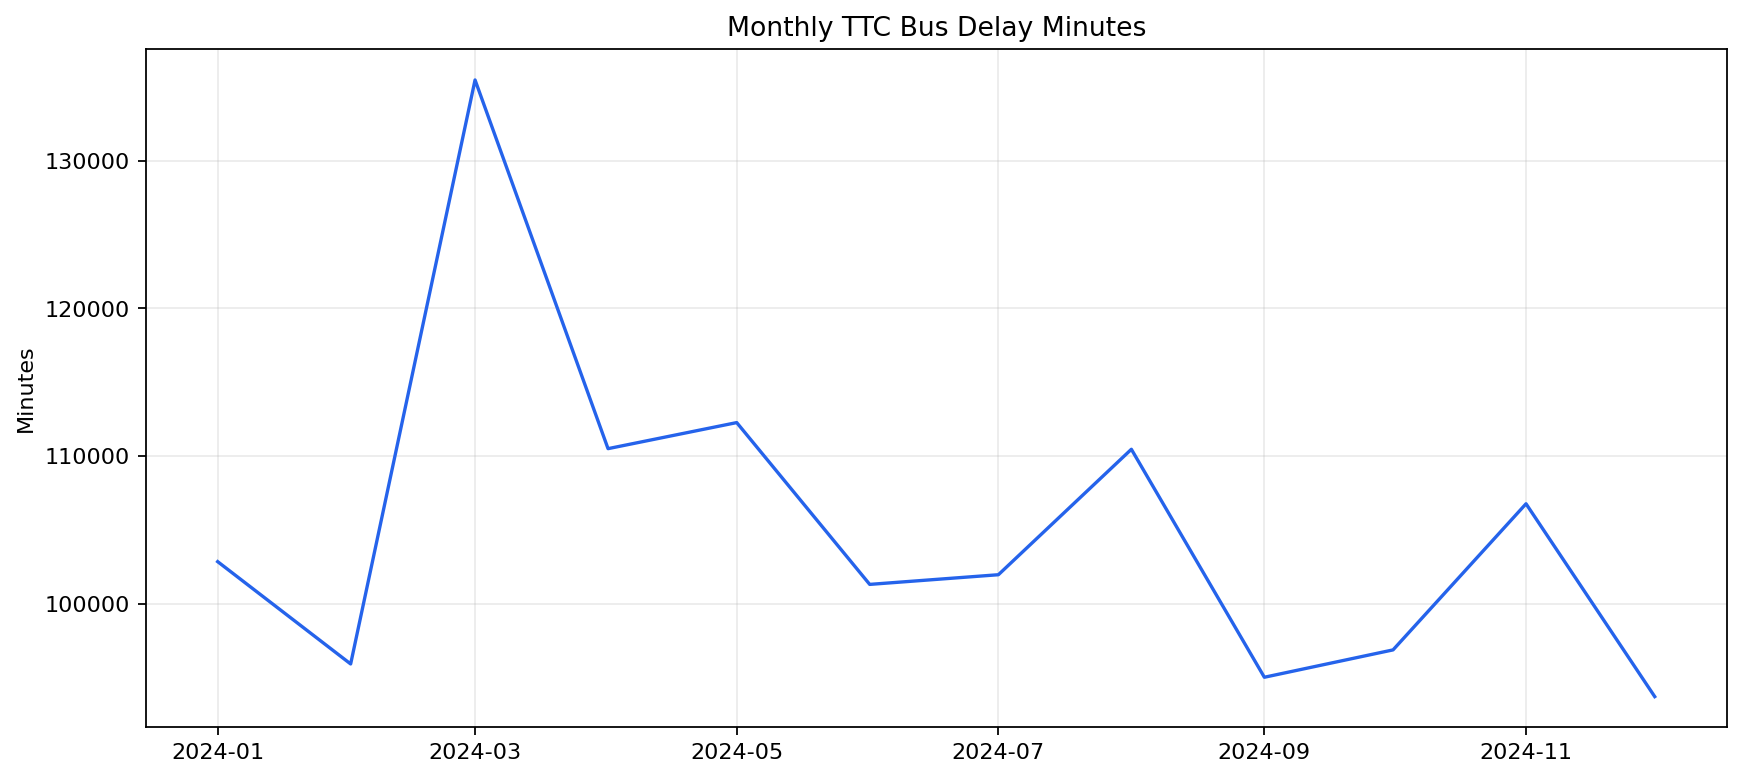

In [2]:
monthly["year_month"] = pd.to_datetime(monthly["year_month"])
monthly = monthly.sort_values("year_month")
figure, axis = plt.subplots(figsize=(11, 5))
axis.plot(monthly["year_month"], monthly["total_delay_minutes"], color="#2563EB")
axis.set(title="Monthly TTC Bus Delay Minutes", ylabel="Minutes")
axis.grid(alpha=0.25)
figure.tight_layout()


### Guide to code step 4

**Read the chart.** The axis labels identify units and the grouping defines what is compared. A visual association does not establish cause. Rate charts need denominators; truncated axes can exaggerate small differences.

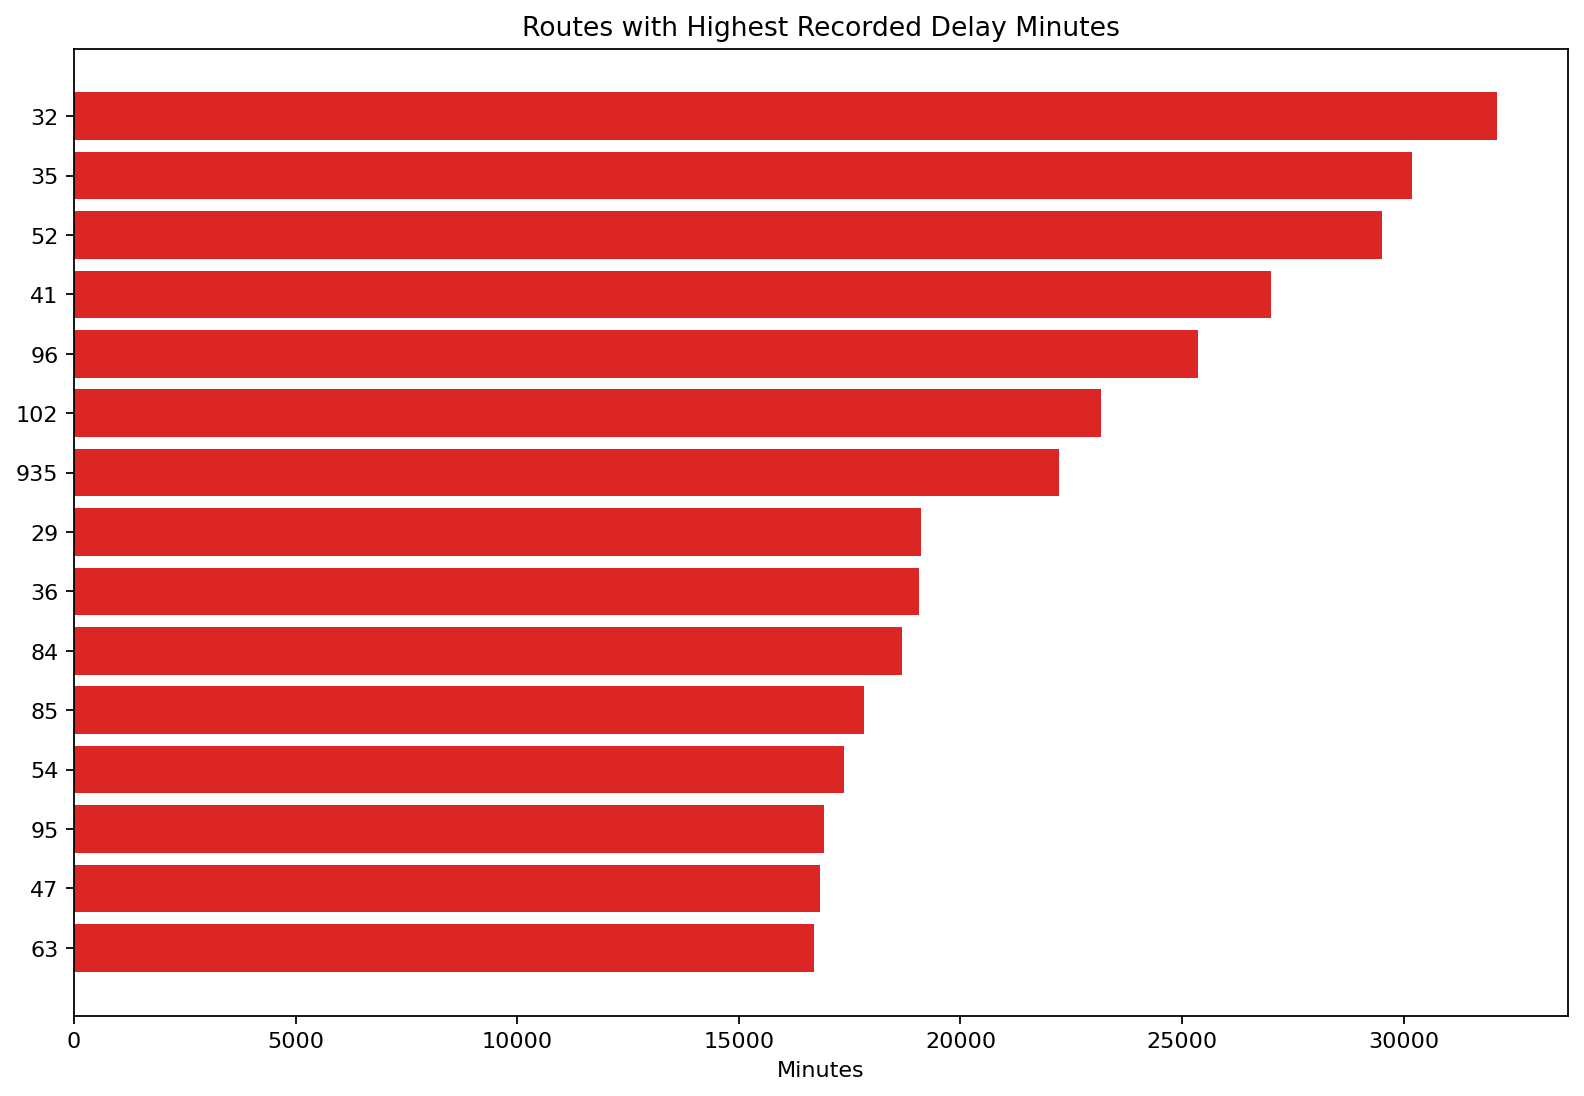

In [3]:
top_routes = routes.head(15).sort_values("total_delay_minutes")
figure, axis = plt.subplots(figsize=(10, 7))
axis.barh(top_routes["route"].astype(str), top_routes["total_delay_minutes"], color="#DC2626")
axis.set(title="Routes with Highest Recorded Delay Minutes", xlabel="Minutes")
figure.tight_layout()


### Guide to code step 5

**Read the chart.** The axis labels identify units and the grouping defines what is compared. A visual association does not establish cause. Rate charts need denominators; truncated axes can exaggerate small differences.

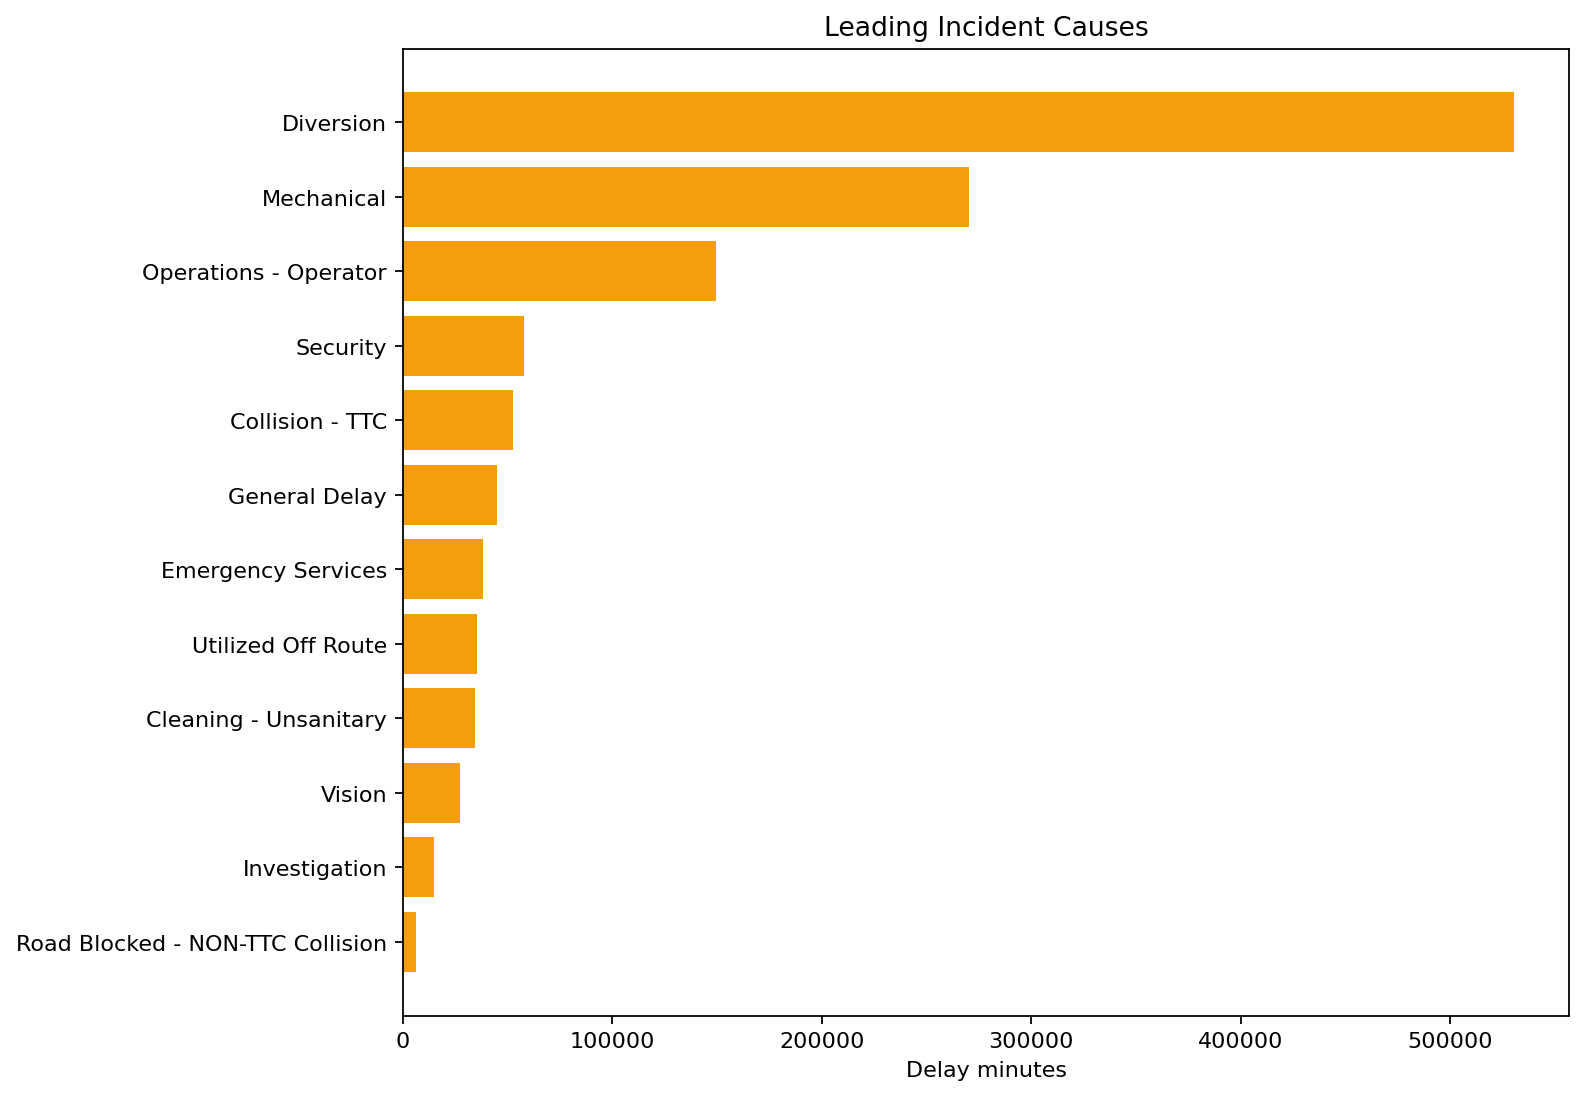

In [4]:
top_incidents = incidents.head(12).sort_values("total_delay_minutes")
figure, axis = plt.subplots(figsize=(10, 7))
axis.barh(top_incidents["incident"], top_incidents["total_delay_minutes"], color="#F59E0B")
axis.set(title="Leading Incident Causes", xlabel="Delay minutes")
figure.tight_layout()


## Findings and final visual results

Fresh execution on 11 October 2026 using the **2024 workbook only**. After the pipeline eligibility filters, **59,021 events** remain, totaling **1,263,332 recorded vehicle-delay minutes**. The leading incident category by minutes is **Diversion**. The values measure recorded incidents, not passenger minutes or delay per scheduled trip.

| Measure | Value |
|---|---:|
| events | 59021 |
| recorded delay minutes | 1263332.0000 |
| source window | 2024 |



Recorded vehicle delay minutes are not passenger time lost. Without service frequency or ridership denominators, high totals do not prove that a route is intrinsically less reliable.

The following figures are copied from saved notebook outputs or the documented evaluation artifacts. Their source and evidence status are given in the research report.


**Figure from key_visuals.ipynb, original code cell 3**

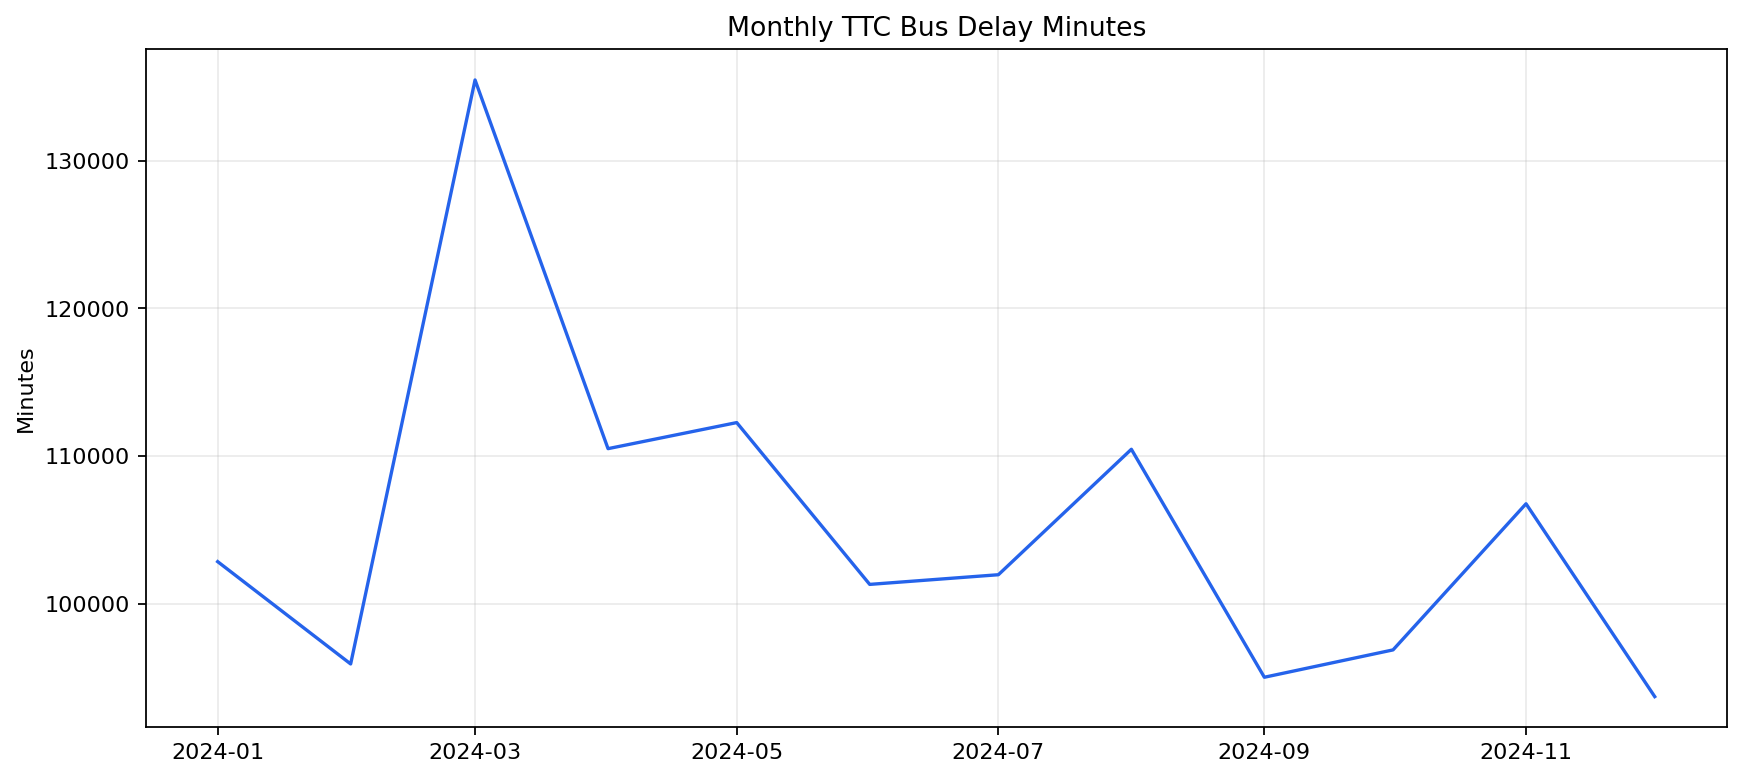

**Figure from key_visuals.ipynb, original code cell 4**

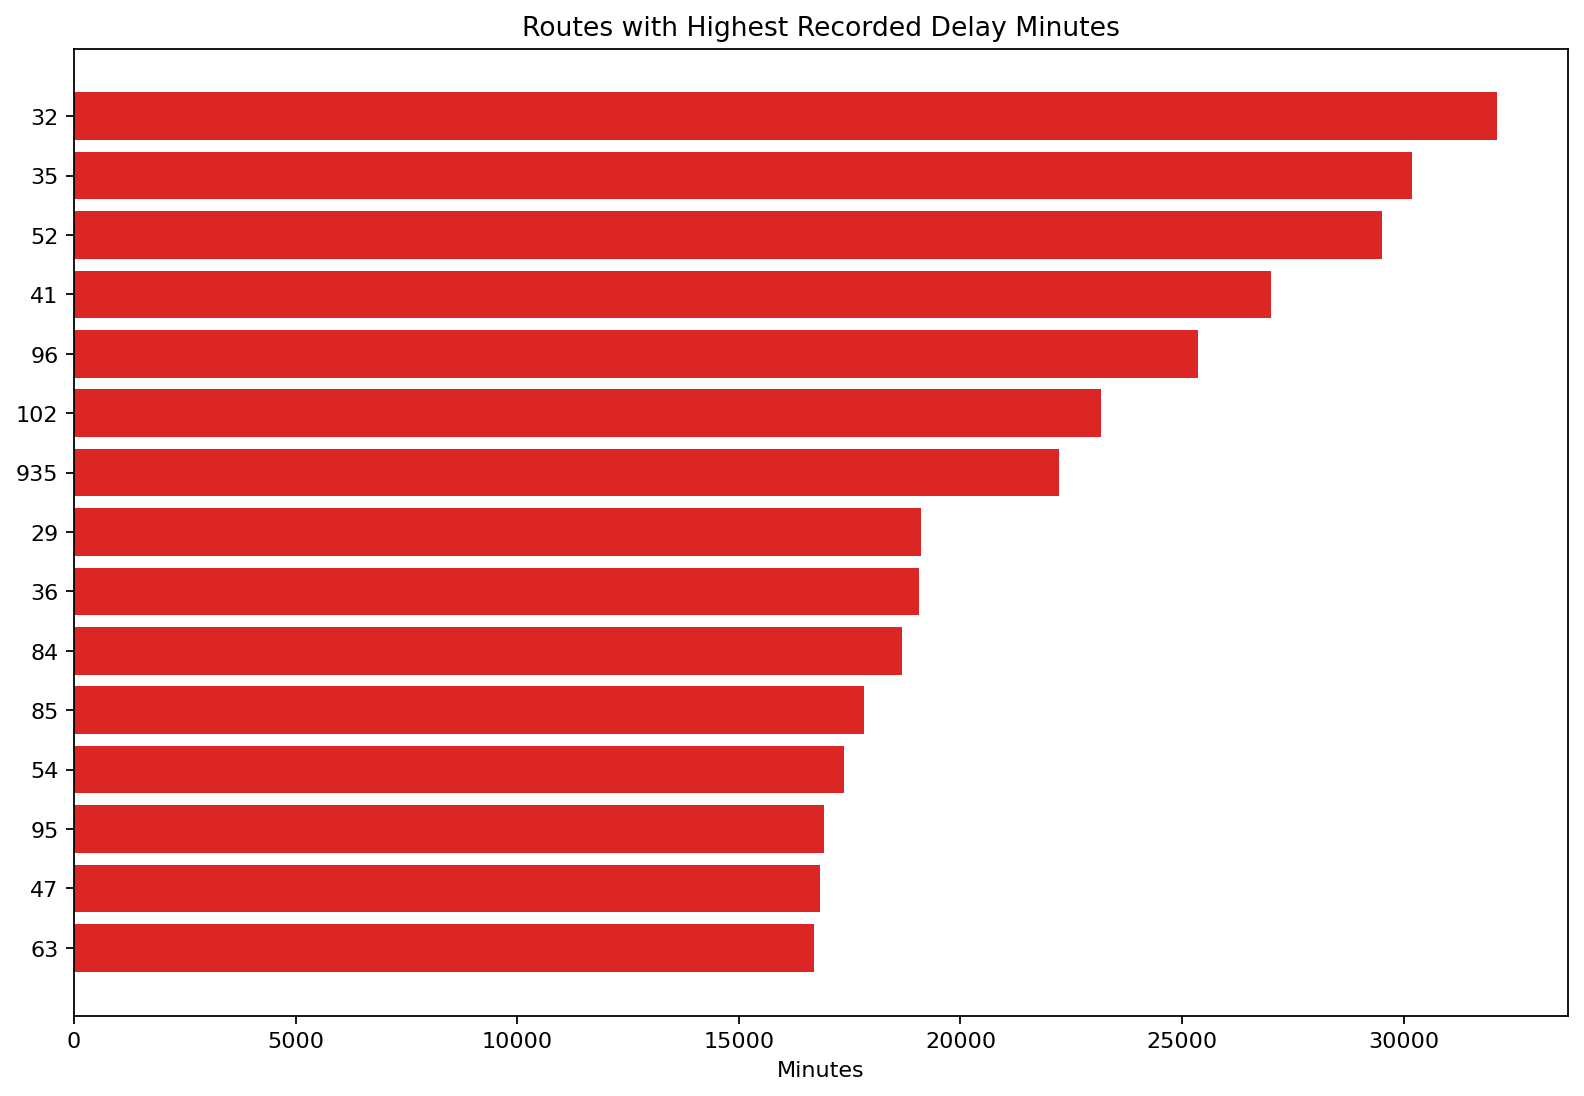

**Figure from key_visuals.ipynb, original code cell 5**

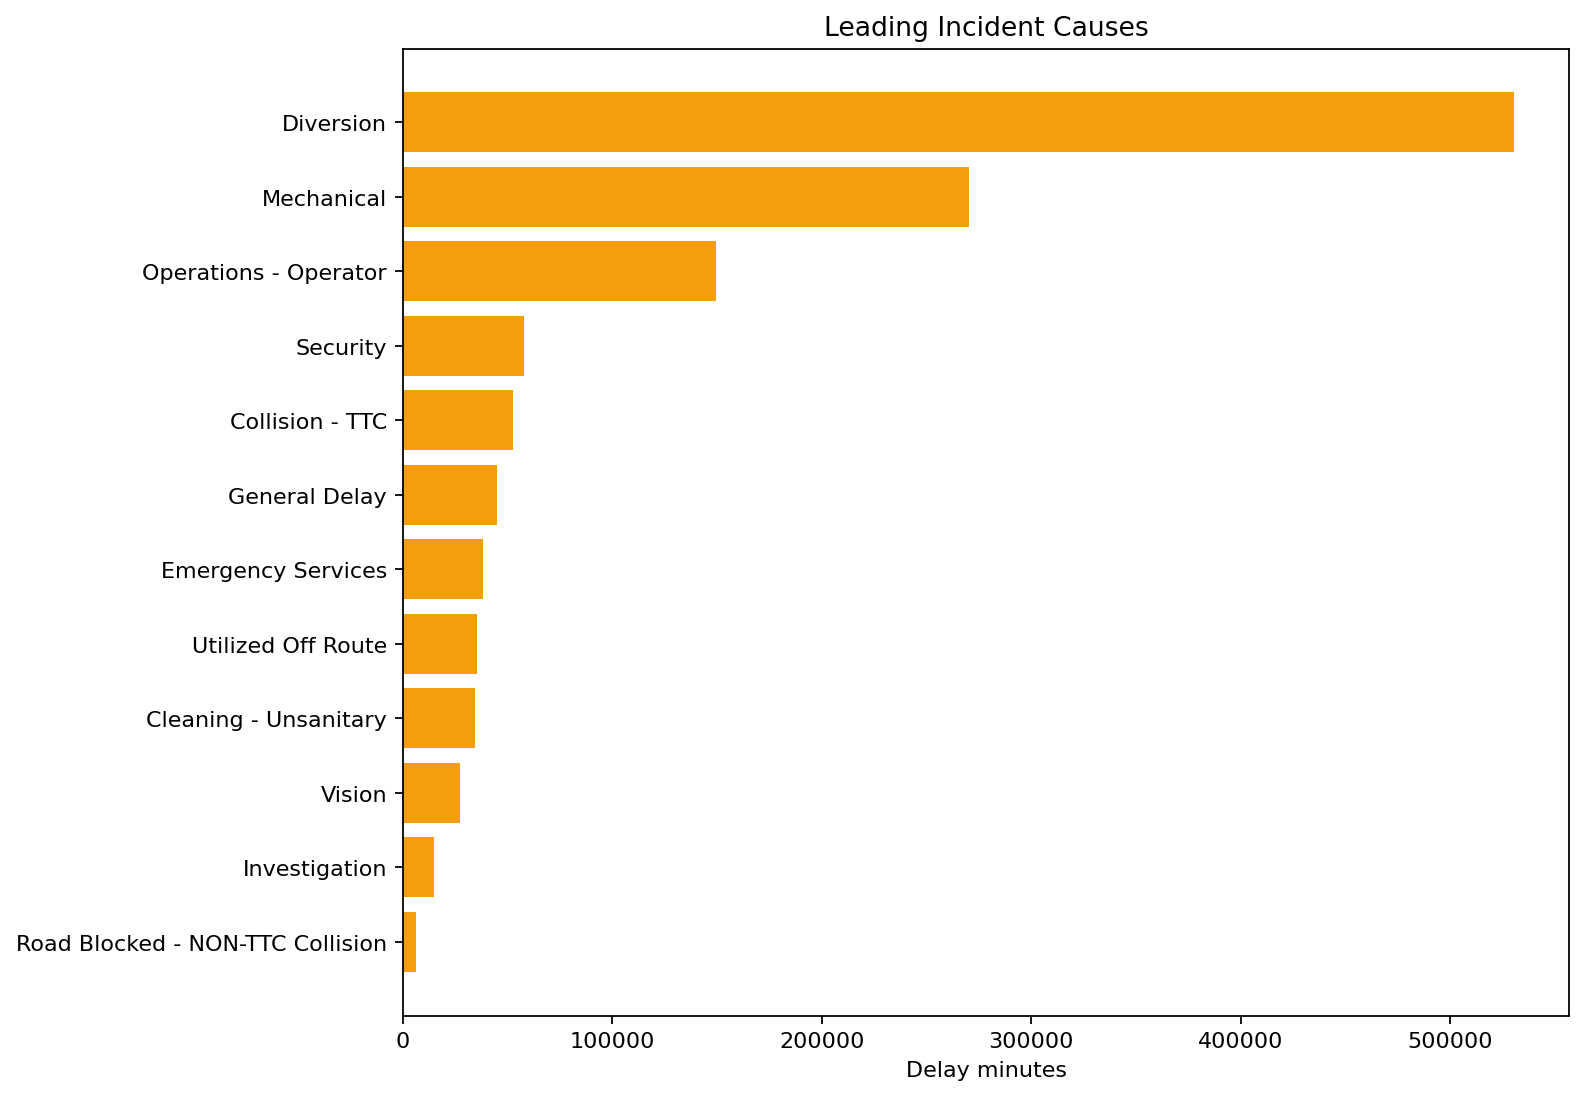